In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
results_23 = pd.read_csv('../data/results_23.csv')
races_23 = pd.read_csv('../data/races_23.csv')
constructors_23 = pd.read_csv('../data/constructors_23.csv')
lap_times_23 = pd.read_csv('../data/lap_times_23.csv')

In [3]:
print(f'Results: {len(results_23)} | Races: {len(races_23)} | Constructors: {len(constructors_23)}')
print(f'Lap times: {len(lap_times_23):,} filas')

Results: 440 | Races: 22 | Constructors: 10
Lap times: 24,386 filas


In [4]:
raceids_2023 = set(races_23['raceId'])
raceids_lap = set(lap_times_23['raceId'])
cobertura = raceids_2023.issubset(raceids_lap)
print(f'Cobertura 2023: {"COMPLETA" if cobertura else "FALTAN DATOS"}')

Cobertura 2023: COMPLETA


In [5]:
# Tabla de puntos F1 2023
PUNTOS_2023 = {
    1: 25, 2: 18, 3: 15, 4: 12, 5: 10,
    6: 8, 7: 6, 8: 4, 9: 2, 10: 1
}

def calcular_puntos(posicion):
    """Devuelve los puntos oficiales de GP 2023 según la posición obtenida.

    Args:
        posicion: Posición numérica del piloto en carrera (1 a 20).

    Returns:
        Entero con los puntos correspondientes según ``PUNTOS_2023`` (0 fuera del top-10).
    """
    return PUNTOS_2023.get(int(posicion), 0)

# Vectorizado
calcular_puntos_vec = np.vectorize(calcular_puntos)

# Mostrar tabla
print('Tabla F1 2023:')
for pos, pts in PUNTOS_2023.items():
    print(f'  P{pos}: {pts} pts')

Tabla F1 2023:
  P1: 25 pts
  P2: 18 pts
  P3: 15 pts
  P4: 12 pts
  P5: 10 pts
  P6: 8 pts
  P7: 6 pts
  P8: 4 pts
  P9: 2 pts
  P10: 1 pts


In [6]:
abandonos_23 = results_23[results_23['statusGeneric'].isin(['Accident', 'Mechanical issue'])].copy()

print(f'Total abandonos con causa en 2023: {len(abandonos_23)}')
print('\nDistribución por tipo:')
print(abandonos_23['statusGeneric'].value_counts())

print(f'\nAbandonos con raceId: {abandonos_23["raceId"].notna().sum()}')
print(f'Abandonos con driverId: {abandonos_23["driverId"].notna().sum()}')
print(f'Abandonos con grid: {abandonos_23["grid"].notna().sum()}')

Total abandonos con causa en 2023: 58

Distribución por tipo:
statusGeneric
Accident            33
Mechanical issue    25
Name: count, dtype: int64

Abandonos con raceId: 58
Abandonos con driverId: 58
Abandonos con grid: 58


In [7]:
# 1. Obtener última vuelta por (raceId, driverId) en lap_times
ultima_vuelta = lap_times_23.groupby(['raceId', 'driverId'])['lap'].max().reset_index()

# 2. Merge para obtener posición en esa última vuelta
ultima_vuelta = ultima_vuelta.merge(
    lap_times_23[['raceId', 'driverId', 'lap', 'position']],
    on=['raceId', 'driverId', 'lap'],
    how='left'
)
ultima_vuelta = ultima_vuelta.rename(columns={'position': 'ultima_posicion'})

# 3. Merge con abandonos
abandonos_con_pos = abandonos_23.merge(
    ultima_vuelta[['raceId', 'driverId', 'ultima_posicion']],
    on=['raceId', 'driverId'],
    how='left'
)

# 4. Fallback: si no hay datos en lap_times, usar grid
abandonos_con_pos['posicion_contrafactual'] = abandonos_con_pos['ultima_posicion'].fillna(abandonos_con_pos['grid'])

In [8]:
# VERIFICACIÓN: NÚMERO de última vuelta vs laps en results_23
# abandonos_23 ya tiene la columna 'laps' (de results_23)
ultima_vuelta_nums = ultima_vuelta[['raceId', 'driverId', 'lap']].rename(columns={'lap': 'ultima_vuelta_num'})

# Merge con abandonos_23 (que ya tiene 'laps')
temp_df = abandonos_23.merge(ultima_vuelta_nums, on=['raceId', 'driverId'], how='left')

# Comparar número de última vuelta vs laps
coinciden = temp_df['ultima_vuelta_num'] == temp_df['laps']

print('=== VERIFICACIÓN: última VUELTA (número) vs laps ===')
print(f'Total abandonos: {len(temp_df)}')
print(f'Coinciden: {coinciden.sum()}')
print(f'NO coinciden: {(~coinciden).sum()}')
print(f'Porcentaje: {coinciden.mean()*100:.1f}%')

if (~coinciden).any():
    print('\nCasos que NO coinciden:')
    print(temp_df[~coinciden][['raceId', 'driverId', 'laps', 'ultima_vuelta_num']])
else:
    print('\n✅ Todos los abandonos coinciden')

=== VERIFICACIÓN: última VUELTA (número) vs laps ===
Total abandonos: 58
Coinciden: 49
NO coinciden: 9
Porcentaje: 84.5%

Casos que NO coinciden:
    raceId  driverId  laps  ultima_vuelta_num
12    1100       844     0                NaN
26    1110       857     0                NaN
31    1112       852     0                NaN
35    1113       852     0                NaN
41    1115         1     0                NaN
42    1115       832     0                NaN
52    1118       825     0                NaN
53    1118       848     0                NaN
54    1118       844     0                NaN


In [9]:
# 5. Calcular puntos perdidos
abandonos_con_pos['puntos_perdidos'] = calcular_puntos_vec(abandonos_con_pos['posicion_contrafactual'])

# 6. Estadísticas
con_cobertura = abandonos_con_pos['ultima_posicion'].notna().sum()
sin_cobertura = abandonos_con_pos['ultima_posicion'].isna().sum()

print(f'Abandonos con datos en lap_times: {con_cobertura}')
print(f'Abandonos usando fallback (grid): {sin_cobertura}')
print(f'Cobertura: {con_cobertura/len(abandonos_con_pos)*100:.1f}%')

Abandonos con datos en lap_times: 49
Abandonos usando fallback (grid): 9
Cobertura: 84.5%


In [10]:
# Agrupar por statusGeneric
puntos_por_tipo = abandonos_con_pos.groupby('statusGeneric').agg({
    'puntos_perdidos': ['sum', 'count', 'mean']
}).round(2)

puntos_por_tipo.columns = ['Puntos perdidos', 'Número abandonos', 'Media pts/abandono']
puntos_por_tipo = puntos_por_tipo.reset_index()

# Mostrar resultados
print('=== PUNTOS PERDIDOS POR TIPO ===')
print(puntos_por_tipo.to_string(index=False))

=== PUNTOS PERDIDOS POR TIPO ===
   statusGeneric  Puntos perdidos  Número abandonos  Media pts/abandono
        Accident               65                33                1.97
Mechanical issue               28                25                1.12


In [11]:
puntos_accident = puntos_por_tipo[puntos_por_tipo['statusGeneric'] == 'Accident']['Puntos perdidos'].values[0]
puntos_mecanico = puntos_por_tipo[puntos_por_tipo['statusGeneric'] == 'Mechanical issue']['Puntos perdidos'].values[0]
n_accident = puntos_por_tipo[puntos_por_tipo['statusGeneric'] == 'Accident']['Número abandonos'].values[0]
n_mecanico = puntos_por_tipo[puntos_por_tipo['statusGeneric'] == 'Mechanical issue']['Número abandonos'].values[0]

print(f'\nAccidentes: {puntos_accident} puntos perdidos ({n_accident} abandonos)')
print(f'Mecánicos: {puntos_mecanico} puntos perdidos ({n_mecanico} abandonos)')
print(f'Diferencia: {puntos_accident - puntos_mecanico} puntos')
print(f'Ratio (Acc/Mec): {puntos_accident / puntos_mecanico:.2f}x')


Accidentes: 65 puntos perdidos (33 abandonos)
Mecánicos: 28 puntos perdidos (25 abandonos)
Diferencia: 37 puntos
Ratio (Acc/Mec): 2.32x


In [12]:
# 1. Calcular puntos reales en carreras terminadas
resultados_terminados = results_23[results_23['statusGeneric'] == 'Finished'].copy()
resultados_terminados['puntos_reales'] = calcular_puntos_vec(resultados_terminados['position'])

# 2. Media de puntos por piloto
media_puntos_piloto = resultados_terminados.groupby('driverId')['puntos_reales'].mean()
conteos_piloto = resultados_terminados.groupby('driverId').size()

# 3. Para pilotos con <3 carreras terminadas, usar media del equipo
driver_constructor_map = results_23.drop_duplicates(['driverId', 'constructorId'])[['driverId', 'constructorId']]
media_puntos_equipo = resultados_terminados.groupby('constructorId')['puntos_reales'].mean()

# Crear serie final de media
media_piloto_final = media_puntos_piloto.copy()
for driver_id in media_puntos_piloto.index:
    if conteos_piloto[driver_id] < 3:
        constructor_id = driver_constructor_map[driver_constructor_map['driverId'] == driver_id]['constructorId'].values
        if len(constructor_id) > 0:
            media_piloto_final[driver_id] = media_puntos_equipo[constructor_id[0]]

# 4. Aplicar a abandonos
abandonos_con_pos['puntos_contrafactual_B'] = abandonos_con_pos['driverId'].map(media_piloto_final)

# 5. Agrupar por tipo
puntos_B_por_tipo = abandonos_con_pos.groupby('statusGeneric').agg({
    'puntos_contrafactual_B': ['sum', 'count', 'mean']
}).round(2)
puntos_B_por_tipo.columns = ['Puntos esperados', 'Número abandonos', 'Media']
puntos_B_por_tipo = puntos_B_por_tipo.reset_index()

# Extraer valores
puntos_B_accident = puntos_B_por_tipo[puntos_B_por_tipo['statusGeneric'] == 'Accident']['Puntos esperados'].values[0]
puntos_B_mecanico = puntos_B_por_tipo[puntos_B_por_tipo['statusGeneric'] == 'Mechanical issue']['Puntos esperados'].values[0]

# Verificar criterios
criterio_B_1 = puntos_B_accident > puntos_B_mecanico
criterio_B_2 = (puntos_B_accident / puntos_B_mecanico) >= 1.5

print('=== CONTRAFACTUAL B (Sensibilidad) ===')
print(puntos_B_por_tipo.to_string(index=False))
print(f'\nAccidentes: {puntos_B_accident:.1f} pts esperados')
print(f'Mecánicos: {puntos_B_mecanico:.1f} pts esperados')
print(f'Ratio: {puntos_B_accident / puntos_B_mecanico:.2f}x')
print(f'\nB1 (Acc > Mec): {"✅" if criterio_B_1 else "❌"}')
print(f'B2 (Ratio >= 1.5x): {"✅" if criterio_B_2 else "❌"}')

=== CONTRAFACTUAL B (Sensibilidad) ===
   statusGeneric  Puntos esperados  Número abandonos  Media
        Accident            133.40                33   4.04
Mechanical issue             93.88                25   3.76

Accidentes: 133.4 pts esperados
Mecánicos: 93.9 pts esperados
Ratio: 1.42x

B1 (Acc > Mec): ✅
B2 (Ratio >= 1.5x): ❌


In [13]:
# Verificar NaN en Contrafactual B
nan_count = abandonos_con_pos['puntos_contrafactual_B'].isna().sum()
print(f'=== VERIFICACIÓN NaN CONTRAFACTUAL B ===')
print(f'Total abandonos: {len(abandonos_con_pos)}')
print(f'NaN en Contrafactual B: {nan_count}')
if nan_count > 0:
    print('Pilotos con NaN:')
    print(abandonos_con_pos[abandonos_con_pos['puntos_contrafactual_B'].isna()][['driverId', 'raceId']])
else:
    print('✅ Sin NaN: todos los pilotos tienen media calculada')

=== VERIFICACIÓN NaN CONTRAFACTUAL B ===
Total abandonos: 58
NaN en Contrafactual B: 0
✅ Sin NaN: todos los pilotos tienen media calculada


In [14]:
# Conteo simple: número de abandonos por tipo
conteo_accident = len(abandonos_23[abandonos_23['statusGeneric'] == 'Accident'])
conteo_mecanico = len(abandonos_23[abandonos_23['statusGeneric'] == 'Mechanical issue'])

# Criterios para conteo simple
criterio_b_1 = conteo_accident > conteo_mecanico
criterio_b_2 = (conteo_accident / conteo_mecanico) >= 1.5

print('=== SENSIBILIDAD (b): CONTEO SIMPLE ===')
print(f'Accidentes: {conteo_accident} abandonos')
print(f'Mecánicos: {conteo_mecanico} abandonos')
print(f'Ratio: {conteo_accident / conteo_mecanico:.2f}x')
print()
print(f'b1 (Acc > Mec): {"✅" if criterio_b_1 else "❌"}')
print(f'b2 (Ratio >= 1.5x): {"✅" if criterio_b_2 else "❌"}')

=== SENSIBILIDAD (b): CONTEO SIMPLE ===
Accidentes: 33 abandonos
Mecánicos: 25 abandonos
Ratio: 1.32x

b1 (Acc > Mec): ✅
b2 (Ratio >= 1.5x): ❌


In [15]:
# Retired de 2023 con mapeo CORRECTO (según docs/informe_retired_statusId31.md)
retired_mapeado = pd.DataFrame({
    'raceId': [1109, 1117, 1120],
    'driverId': [858, 858, 832],
    'constructorId': [3, 3, 6],
    'statusGeneric': ['Other', 'Mechanical issue', 'Other'],
    'puntos_contrafactual': [0, 0, 0]
})

# Filtrar solo F y D (excluir O)
retired_validos = retired_mapeado[retired_mapeado['statusGeneric'] != 'Other'].copy()

print("Retired mapeados válidos (F→Mechanical, D→Accident):")
print(retired_validos[['raceId', 'driverId', 'statusGeneric']])
print(f"\nTotal a añadir: {len(retired_validos)} casos")
print(f"Distribución: {retired_validos['statusGeneric'].value_counts().to_dict()}")

Retired mapeados válidos (F→Mechanical, D→Accident):
   raceId  driverId     statusGeneric
1    1117       858  Mechanical issue

Total a añadir: 1 casos
Distribución: {'Mechanical issue': 1}


In [16]:
# Combinar Retired válidos con abandonos originales
abandonos_con_retired = pd.concat([
    abandonos_23,
    retired_validos[['raceId', 'driverId', 'constructorId', 'statusGeneric']]
], ignore_index=True)

# Recalcular conteo simple con Retired mapeados
conteo_accident_retired = len(abandonos_con_retired[abandonos_con_retired['statusGeneric'] == 'Accident'])
conteo_mecanico_retired = len(abandonos_con_retired[abandonos_con_retired['statusGeneric'] == 'Mechanical issue'])

# GUARDAR la variable c1 para usarla en cell 15
c1 = conteo_accident_retired > conteo_mecanico_retired

print('=== CONTEO SIMPLE (c): RETIRED MAPEADO ===')
print(f'Accidentes: {conteo_accident_retired} abandonos')
print(f'Mecánicos: {conteo_mecanico_retired} abandonos')
print(f'Ratio: {conteo_accident_retired / conteo_mecanico_retired:.2f}x')
print(f'\nc1 (Acc > Mec): {"✅" if c1 else "❌"}')

=== CONTEO SIMPLE (c): RETIRED MAPEADO ===
Accidentes: 33 abandonos
Mecánicos: 26 abandonos
Ratio: 1.27x

c1 (Acc > Mec): ✅


In [17]:
# Evaluar criterio 3: consistente en >=2 de 3 sensibilidades
# (a) Contrafactual B: criterio_B_1
# (b) Conteo simple: criterio_b_1
# (c) Retired mapeado: c1

sensibilidades_cumplen = [
    criterio_B_1,  # Contrafactual B (cell 12)
    criterio_b_1,  # Conteo simple (cell 13)
    c1              # Retired mapeado (cell 15)
]

criterio_3 = sum(sensibilidades_cumplen) >= 2

print('=== EVALUACIÓN CRITERIO 3 ===')
print(f'(a) Contrafactual B: {"✅ CUMPLE" if criterio_B_1 else "❌ NO CUMPLE"}')
print(f'(b) Conteo simple: {"✅ CUMPLE" if criterio_b_1 else "❌ NO CUMPLE"}')
print(f'(c) Retired mapeado: {"✅ CUMPLE" if c1 else "❌ NO CUMPLE"}')
print(f'\nCriterio 3 (≥2 de 3 sensibilidades cumplen Acc > Mec): {"✅ CUMPLE" if criterio_3 else "❌ NO CUMPLE"}')

=== EVALUACIÓN CRITERIO 3 ===
(a) Contrafactual B: ✅ CUMPLE
(b) Conteo simple: ✅ CUMPLE
(c) Retired mapeado: ✅ CUMPLE

Criterio 3 (≥2 de 3 sensibilidades cumplen Acc > Mec): ✅ CUMPLE


In [18]:
# CONCLUSIÓN FINAL COMPLETA (3 criterios)
# Recalcular criterios 1 y 2 (por si no están en scope)
criterio_1 = puntos_accident > puntos_mecanico
criterio_2 = (puntos_accident / puntos_mecanico) >= 1.5

print('=== CONCLUSIÓN FINAL H4 ===')
print(f'Criterio 1 (Contrafactual A - Acc > Mec): {"✅ CUMPLE" if criterio_1 else "❌ NO CUMPLE"}')
print(f'  {puntos_accident} > {puntos_mecanico}')
print(f'Criterio 2 (Contrafactual A - Ratio >= 1.5x): {"✅ CUMPLE" if criterio_2 else "❌ NO CUMPLE"}')
print(f'  {puntos_accident / puntos_mecanico:.2f}x >= 1.5x')
print(f'Criterio 3 (≥2 de 3 sensibilidades): {"✅ CUMPLE" if criterio_3 else "❌ NO CUMPLE"}')
print(f'  (a) Contrafactual B: {"✅" if criterio_B_1 else "❌"}, (b) Conteo simple: {"✅" if criterio_b_1 else "❌"}, (c) Retired: {"✅" if c1 else "❌"}')
print(f'\n→ H4 {"SE CONFIRMA ✅" if (criterio_1 and criterio_2 and criterio_3) else "NO SE CONFIRMA ❌"}')

=== CONCLUSIÓN FINAL H4 ===
Criterio 1 (Contrafactual A - Acc > Mec): ✅ CUMPLE
  65 > 28
Criterio 2 (Contrafactual A - Ratio >= 1.5x): ✅ CUMPLE
  2.32x >= 1.5x
Criterio 3 (≥2 de 3 sensibilidades): ✅ CUMPLE
  (a) Contrafactual B: ✅, (b) Conteo simple: ✅, (c) Retired: ✅

→ H4 SE CONFIRMA ✅


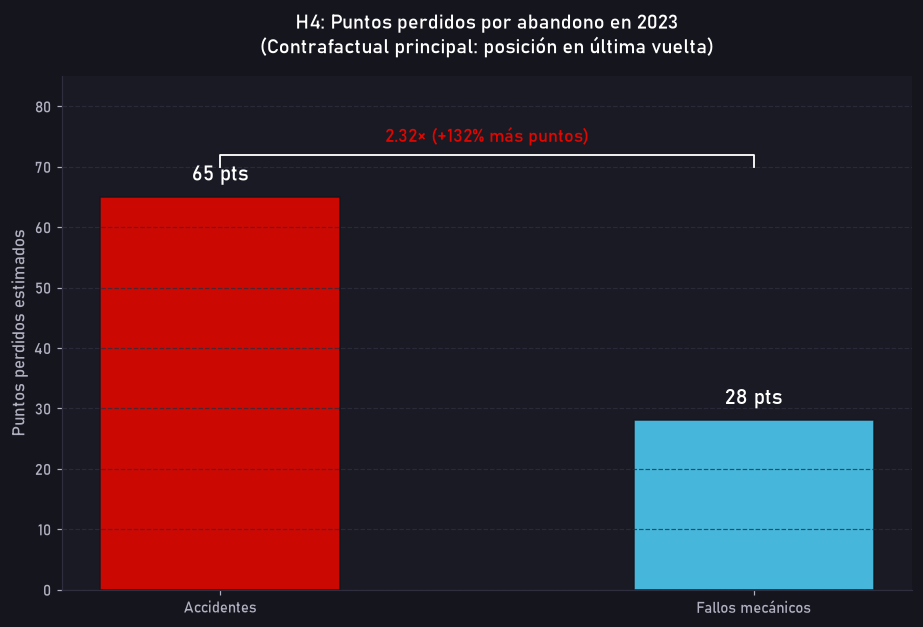

In [19]:
# ==============================================================================
# Gráfica H4 (Opción 1): Golpe directo (Aislada con plt.rc_context)
# ==============================================================================
BG_COLOR    = '#15151E'   # Fondo negro carbón oficial F1
AX_COLOR    = '#1A1A24'   # Fondo interior de los ejes
ROJO_F1     = '#E10600'   # Rojo F1 (Accidentes)
AZUL_MEC    = '#4CC9F0'   # Azul acero (Mecánicos)
BLANCO_F1   = '#FFFFFF'   # Texto principal
PLATA_F1    = '#B0B0C0'   # Textos secundarios y ejes
GRID_COLOR  = '#2E2E3E'   # Rejilla oscura sutil

causas = ['Accidentes', 'Fallos mecánicos']
puntos = [puntos_accident, puntos_mecanico]
colores = [ROJO_F1, AZUL_MEC]

with plt.rc_context({
    'font.family': 'Bahnschrift',
    'axes.titleweight': 'bold',
    'axes.titlesize': 14,
    'axes.titlepad': 15,
    'axes.labelsize': 11,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'grid.color': GRID_COLOR,
    'grid.linestyle': '--',
    'grid.alpha': 0.8,
    'legend.frameon': False,
    'figure.facecolor': BG_COLOR,
    'axes.facecolor': AX_COLOR
}):
    fig, ax = plt.subplots(figsize=(8.5, 5.8))

    bars = ax.bar(causas, puntos, color=colores, width=0.45, alpha=0.9, edgecolor=BG_COLOR)

    # Valores sobre las barras
    for bar, pts in zip(bars, puntos):
        ax.text(
            bar.get_x() + bar.get_width()/2, 
            pts + 2, 
            f'{int(pts)} pts', 
            ha='center', va='bottom', fontsize=14, fontweight='bold', color=BLANCO_F1
        )

    # Llave comparativa del ratio 2.32x
    y_line = max(puntos) + 7
    ax.plot([0, 0, 1, 1], [y_line - 2, y_line, y_line, y_line - 2], color=BLANCO_F1, lw=1.2)
    ax.text(
        0.5, y_line + 1.5, 
        '2.32× (+132% más puntos)', 
        ha='center', va='bottom', 
        fontsize=12, fontweight='bold', color=ROJO_F1
    )

    ax.set_title('H4: Puntos perdidos por abandono en 2023\n(Contrafactual principal: posición en última vuelta)', 
                 fontsize=13, pad=15, color=BLANCO_F1)
    ax.set_ylabel('Puntos perdidos estimados', color=PLATA_F1)
    ax.tick_params(colors=PLATA_F1)
    ax.set_ylim(0, 85)
    ax.grid(axis='y')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color(GRID_COLOR)
    ax.spines['bottom'].set_color(GRID_COLOR)

    plt.tight_layout()
    plt.show()

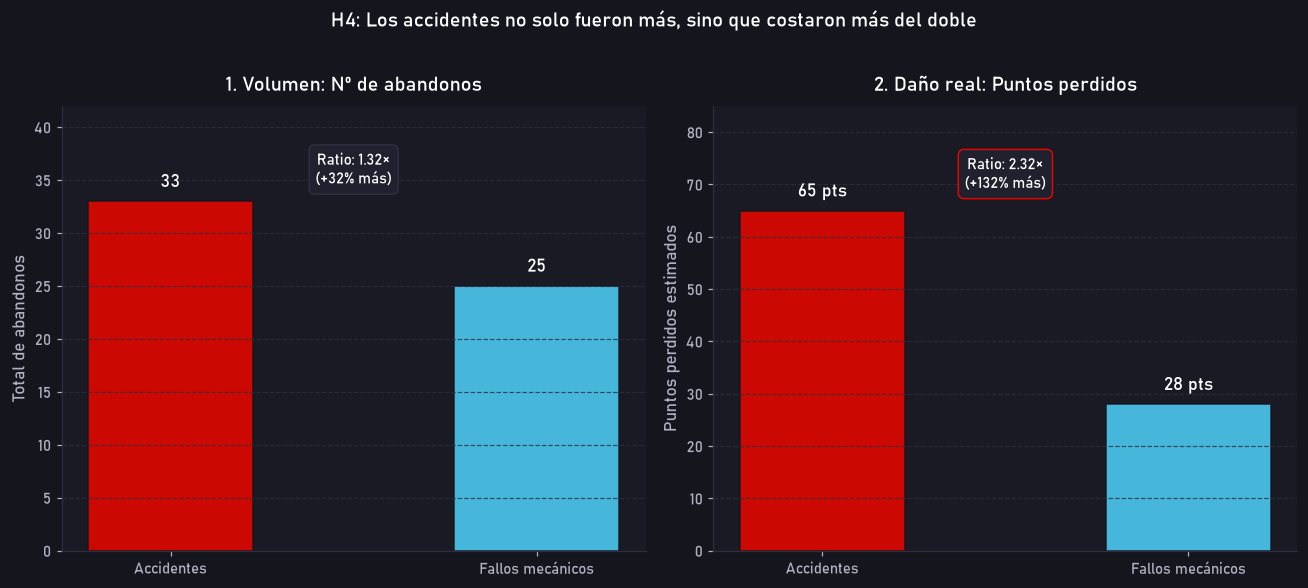

In [20]:
# ==============================================================================
# Gráfica H4 (Opción 2): Volumen vs Daño Real (Aislada con plt.rc_context)
# ==============================================================================
BG_COLOR    = '#15151E'   # Fondo negro carbón oficial F1
AX_COLOR    = '#1A1A24'   # Fondo interior de los ejes
ROJO_F1     = '#E10600'   # Rojo F1 (Accidentes)
AZUL_MEC    = '#4CC9F0'   # Azul acero (Mecánicos)
BLANCO_F1   = '#FFFFFF'   # Texto principal
PLATA_F1    = '#B0B0C0'   # Textos secundarios y ejes
GRID_COLOR  = '#2E2E3E'   # Rejilla oscura sutil

causas = ['Accidentes', 'Fallos mecánicos']
colores = [ROJO_F1, AZUL_MEC]

with plt.rc_context({
    'font.family': 'Bahnschrift',
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.titlepad': 12,
    'axes.labelsize': 11,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'grid.color': GRID_COLOR,
    'grid.linestyle': '--',
    'grid.alpha': 0.8,
    'legend.frameon': False,
    'figure.facecolor': BG_COLOR,
    'axes.facecolor': AX_COLOR
}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2))

    # Panel 1: Número de abandonos
    bars1 = ax1.bar(causas, [n_accident, n_mecanico], color=colores, width=0.45, alpha=0.9, edgecolor=BG_COLOR)
    for bar, val in zip(bars1, [n_accident, n_mecanico]):
        ax1.text(bar.get_x() + bar.get_width()/2, val + 1, f'{val}', ha='center', va='bottom', fontsize=12, fontweight='bold', color=BLANCO_F1)

    ax1.set_title('1. Volumen: Nº de abandonos', color=BLANCO_F1, pad=10)
    ax1.set_ylabel('Total de abandonos', color=PLATA_F1)
    ax1.tick_params(colors=PLATA_F1)
    ax1.set_ylim(0, 42)
    ax1.grid(axis='y')
    ax1.text(
        0.5, 36, 'Ratio: 1.32×\n(+32% más)', ha='center', va='center', fontsize=10, color=BLANCO_F1,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#20202E', edgecolor=GRID_COLOR)
    )
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['left'].set_color(GRID_COLOR)
    ax1.spines['bottom'].set_color(GRID_COLOR)

    # Panel 2: Puntos perdidos (Daño real)
    bars2 = ax2.bar(causas, [puntos_accident, puntos_mecanico], color=colores, width=0.45, alpha=0.9, edgecolor=BG_COLOR)
    for bar, val in zip(bars2, [puntos_accident, puntos_mecanico]):
        ax2.text(bar.get_x() + bar.get_width()/2, val + 2, f'{int(val)} pts', ha='center', va='bottom', fontsize=12, fontweight='bold', color=BLANCO_F1)

    ax2.set_title('2. Daño real: Puntos perdidos', color=BLANCO_F1, pad=10)
    ax2.set_ylabel('Puntos perdidos estimados', color=PLATA_F1)
    ax2.tick_params(colors=PLATA_F1)
    ax2.set_ylim(0, 85)
    ax2.grid(axis='y')
    ax2.text(
        0.5, 72, 'Ratio: 2.32×\n(+132% más)', ha='center', va='center', fontsize=10, fontweight='bold', color=BLANCO_F1,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#20202E', edgecolor=ROJO_F1)
    )
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.spines['left'].set_color(GRID_COLOR)
    ax2.spines['bottom'].set_color(GRID_COLOR)

    fig.suptitle('H4: Los accidentes no solo fueron más, sino que costaron más del doble', fontsize=13, fontweight='bold', color=BLANCO_F1, y=1.02)

    plt.tight_layout()
    plt.show()